In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [61]:
df = pd.read_csv('lego_sets.csv')
df.head()

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,country
0,6-12,29.99,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,Average,Bird Island Egg Heist,4.5,Angry Birds™,4.0,US
1,6-12,19.99,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,Easy,Piggy Plane Attack,5.0,Angry Birds™,4.0,US
2,6-12,12.99,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,Easy,Piggy Car Escape,4.3,Angry Birds™,4.1,US
3,12+,99.99,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,Average,United States Capitol Building,4.6,Architecture,4.3,US
4,12+,79.99,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,Challenging,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,US


## Step0: Quick copypaste data cleaning from exercise 1

In [62]:
# This code makes the column 'continent' instead of country, which can be then turned into three separate columns.

country_to_continent = {
    'US': 'North America',
    'CA': 'North America',
    'AU': 'Oceania',
    'NZ': 'Oceania',
    'AT': 'Europe',
    'BE': 'Europe',
    'CH': 'Europe',
    'CZ': 'Europe',
    'DE': 'Europe',
    'DN': 'Europe',   
    'ES': 'Europe',
    'FI': 'Europe',
    'FR': 'Europe',
    'GB': 'Europe',
    'IE': 'Europe',
    'IT': 'Europe',
    'LU': 'Europe',
    'NO': 'Europe',
    'NL': 'Europe',
    'PL': 'Europe',
    'PT': 'Europe',
}

df['continent'] = df['country'].map(country_to_continent)
df = df.drop('country', axis=1)

In [63]:
# Separate the 'continent' column to it's own columns

df = pd.get_dummies(df, columns=['continent'], dtype=int)
df.head()

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,continent_Europe,continent_North America,continent_Oceania
0,6-12,29.99,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,Average,Bird Island Egg Heist,4.5,Angry Birds™,4.0,0,1,0
1,6-12,19.99,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,Easy,Piggy Plane Attack,5.0,Angry Birds™,4.0,0,1,0
2,6-12,12.99,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,Easy,Piggy Car Escape,4.3,Angry Birds™,4.1,0,1,0
3,12+,99.99,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,Average,United States Capitol Building,4.6,Architecture,4.3,0,1,0
4,12+,79.99,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,Challenging,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,0,1,0


In [64]:
# Creating a new column 'price_per_brick' for more fun comparisons
# Some legosets might be more expensive even with less bricks than other sets
# Only for analytic purposes, doesn't work in ML

df['price_per_brick'] = df['list_price'] / df['piece_count']
df['price_per_brick'] = df['price_per_brick'].round(4)
df['price_per_brick']


0        0.1083
1        0.1190
2        0.1755
3        0.0969
4        0.1075
          ...  
12256    0.1073
12257    0.1124
12258    0.1047
12259    0.2539
12260    0.1118
Name: price_per_brick, Length: 12261, dtype: float64

In [65]:
# This code is 98% claude
# The primary function is to separate the 'ages' column into two different columns - min and max ages

import re

def parse_min_age(age_str):
    if pd.isna(age_str):
        return None

    age_str = str(age_str).strip()
    age_str = age_str.replace('½', '.5')  # handle fractions like 1½ -> 1.5

    # Grab the first number in the string. This covers "12+", "12-16", and "2".
    match = re.search(r'\d*\.?\d+', age_str)
    return float(match.group()) if match else None

df['min_age'] = df['ages'].apply(parse_min_age)

In [66]:
# Mapping the review_difficulty column
review_mapper = {'Very Easy': 0, 'Easy': 1, 'Average': 2, 'Challenging': 3, 'Very Challenging': 4}
df['review_difficulty'] = df['review_difficulty'].map(review_mapper)

In [67]:
# dropping unnessary columns, most of these columns are just set names or descriptions of the sets
droppables = ['prod_desc', 'prod_long_desc', 'set_name', 'ages', 'prod_id']
df = df.drop(droppables, axis=1)

In [68]:
df = df.dropna()
df = df.drop_duplicates()

## Step 1a: Select 1 categorical feature containing high cardinality

In [69]:
df['theme_name']

0                  Angry Birds™
1                  Angry Birds™
2                  Angry Birds™
3                  Architecture
4                  Architecture
                  ...          
12131                Star Wars™
12145                Star Wars™
12193                Star Wars™
12194                Star Wars™
12224    THE LEGO® BATMAN MOVIE
Name: theme_name, Length: 5889, dtype: object

## Step 1b: Show the number of unique values in your selected high-cardinality feature

In [70]:
# how many categories do we have?
print(f"Total categories: {df['theme_name'].nunique()}")

df['theme_name'].value_counts()



Total categories: 38


theme_name
Star Wars™                               891
City                                     610
DUPLO®                                   319
Technic                                  314
Friends                                  310
THE LEGO® BATMAN MOVIE                   261
Marvel Super Heroes                      255
THE LEGO® NINJAGO® MOVIE™                252
Creator 3-in-1                           244
BrickHeadz                               239
Creator Expert                           208
Juniors                                  206
Classic                                  174
Minecraft™                               172
Speed Champions                          169
Disney™                                  168
DIMENSIONS™                              150
Architecture                             137
NINJAGO®                                 114
DC Comics™ Super Heroes                  106
Elves                                     98
NEXO KNIGHTS™                             88

Looks like this one column has a very high cardinality with it's themes. 38 different categories in total.

## Step 1c: Use a robust high cardinality reduction technique to solve it.

In [71]:
# Going to try agglomerative clustering


# it's possible to add more aggregations:
# Median
# Standard deviation
# Minimum and maximum
# Transaction count
# Possibly selected percentiles

# this is also just one use case of agglomerative clustering
# you can use it also for conventional clustering

# you can also study the hierarchies from a dendrogram
# and cut it into more broad clusters

category_aggregates = df.groupby('theme_name').agg({
    'list_price': 'mean',
    'num_reviews': 'mean',
    'piece_count': 'mean',
    'play_star_rating': 'mean',
    'price_per_brick': 'mean',
    'min_age': 'mean',
    'review_difficulty': 'mean',
    'star_rating': 'mean',
    'val_star_rating': 'mean',
    'theme_name': 'count'
}).rename(columns={'theme_name': 'size'}).reset_index()

category_aggregates

,theme_name,list_price,num_reviews,piece_count,play_star_rating,price_per_brick,min_age,review_difficulty,star_rating,val_star_rating,size
0,Angry Birds™,21.021100,5.000000,173.000000,4.100000,0.133317,6.000000,1.333333,4.600000,4.033333,6
1,Architecture,64.236413,21.299270,574.080292,3.732847,0.112867,12.000000,2.000000,4.607299,4.199270,137
2,BOOST,197.211323,63.000000,847.000000,3.800000,0.232838,7.000000,2.000000,3.400000,3.500000,13
3,BrickHeadz,15.568493,3.719665,169.849372,3.428033,0.100959,10.000000,0.815900,4.680335,4.470293,239
4,Carnotaurus Gyrosphere Escape,106.490211,2.000000,577.000000,5.000000,0.184556,7.000000,2.000000,5.000000,4.000000,9
5,City,52.306664,14.222951,332.954098,4.364918,0.549624,5.460656,1.185246,4.391148,4.030656,610
6,Classic,18.551160,22.057471,197.534483,4.355747,3.017674,4.000000,0.695402,4.454598,4.371839,174
7,Creator 3-in-1,35.344529,8.127049,332.536885,4.278689,0.108259,7.278689,1.508197,4.406148,4.382377,244
8,Creator Expert,204.630461,121.331731,2584.163462,4.319231,0.085031,15.692308,2.716346,4.648558,4.419712,208
9,DC Comics™ Super Heroes,57.873757,8.443396,442.584906,4.583962,0.135942,6.811321,1.594340,4.588679,4.363208,106


In [72]:
from sklearn.preprocessing import StandardScaler

# select the aggregate features we want to use
# and potentially scale
features = [
    'list_price',
    'num_reviews',
    'piece_count',
    'play_star_rating',
    'price_per_brick',
    'min_age',
    'review_difficulty',
    'star_rating',
    'val_star_rating'
]


# scaling is not strictly required by agglomerative clustering
# but it can be helpful => try with and without scaling
# scaler = StandardScaler()

# X_scaled = scaler.fit_transform(
#     category_aggregates[features]
# )

X_scaled = category_aggregates[features]

In [73]:
X_scaled

,list_price,num_reviews,piece_count,play_star_rating,price_per_brick,min_age,review_difficulty,star_rating,val_star_rating
0,21.021100,5.000000,173.000000,4.100000,0.133317,6.000000,1.333333,4.600000,4.033333
1,64.236413,21.299270,574.080292,3.732847,0.112867,12.000000,2.000000,4.607299,4.199270
2,197.211323,63.000000,847.000000,3.800000,0.232838,7.000000,2.000000,3.400000,3.500000
3,15.568493,3.719665,169.849372,3.428033,0.100959,10.000000,0.815900,4.680335,4.470293
4,106.490211,2.000000,577.000000,5.000000,0.184556,7.000000,2.000000,5.000000,4.000000
5,52.306664,14.222951,332.954098,4.364918,0.549624,5.460656,1.185246,4.391148,4.030656
6,18.551160,22.057471,197.534483,4.355747,3.017674,4.000000,0.695402,4.454598,4.371839
7,35.344529,8.127049,332.536885,4.278689,0.108259,7.278689,1.508197,4.406148,4.382377
8,204.630461,121.331731,2584.163462,4.319231,0.085031,15.692308,2.716346,4.648558,4.419712
9,57.873757,8.443396,442.584906,4.583962,0.135942,6.811321,1.594340,4.588679,4.363208


In [74]:
# Combining themes into clusters with agglomerative clustering

from sklearn.cluster import AgglomerativeClustering

clusterer = AgglomerativeClustering(
    n_clusters=8, # I'm using the default 8 the teacher used, just to try it out
    linkage='ward'
)

category_aggregates['Cluster'] = clusterer.fit_predict(X_scaled)

## Step 1d: Report on your results.

In [75]:
# Lets see which themes were combined into which clusters.

for cluster in sorted(category_aggregates['Cluster'].unique()):
    categories = category_aggregates.loc[
        category_aggregates['Cluster'] == cluster,
        'theme_name'
    ].tolist()

    print(f"\nCluster {cluster}:")
    print(categories)

    # NOTE: similar cluster/categories tend to group together

    # this way the cluster seems like an ordinal category, but technically
    # it's still just a nominal category (you might need OneHotEncoding for the cluster!)




Cluster 0:
['Angry Birds™', 'BrickHeadz', 'Classic', 'DIMENSIONS™', 'DUPLO®', 'Juniors', 'MINDSTORMS®', 'Minifigures', 'Power Functions', 'Pteranodon Chase', 'Stygimoloch Breakout']

Cluster 1:
['BOOST', 'Disney™', 'THE LEGO® BATMAN MOVIE']

Cluster 2:
['City', 'Creator 3-in-1', 'DC Comics™ Super Heroes', 'DC Super Hero Girls', 'Dilophosaurus Outpost Attack', 'Elves', 'Friends', 'Jurassic Park Velociraptor Chase', 'LEGO® Creator 3-in-1', 'Marvel Super Heroes', 'Speed Champions']

Cluster 3:
['Ghostbusters™']

Cluster 4:
['Ideas', 'Indoraptor Rampage at Lockwood Estate', 'THE LEGO® NINJAGO® MOVIE™', 'Technic']

Cluster 5:
['SERIOUS PLAY®']

Cluster 6:
['Architecture', 'Carnotaurus Gyrosphere Escape', 'Minecraft™', 'NEXO KNIGHTS™', 'NINJAGO®', 'Star Wars™']

Cluster 7:
['Creator Expert']


Studying the hierarchies with a dendrogram!

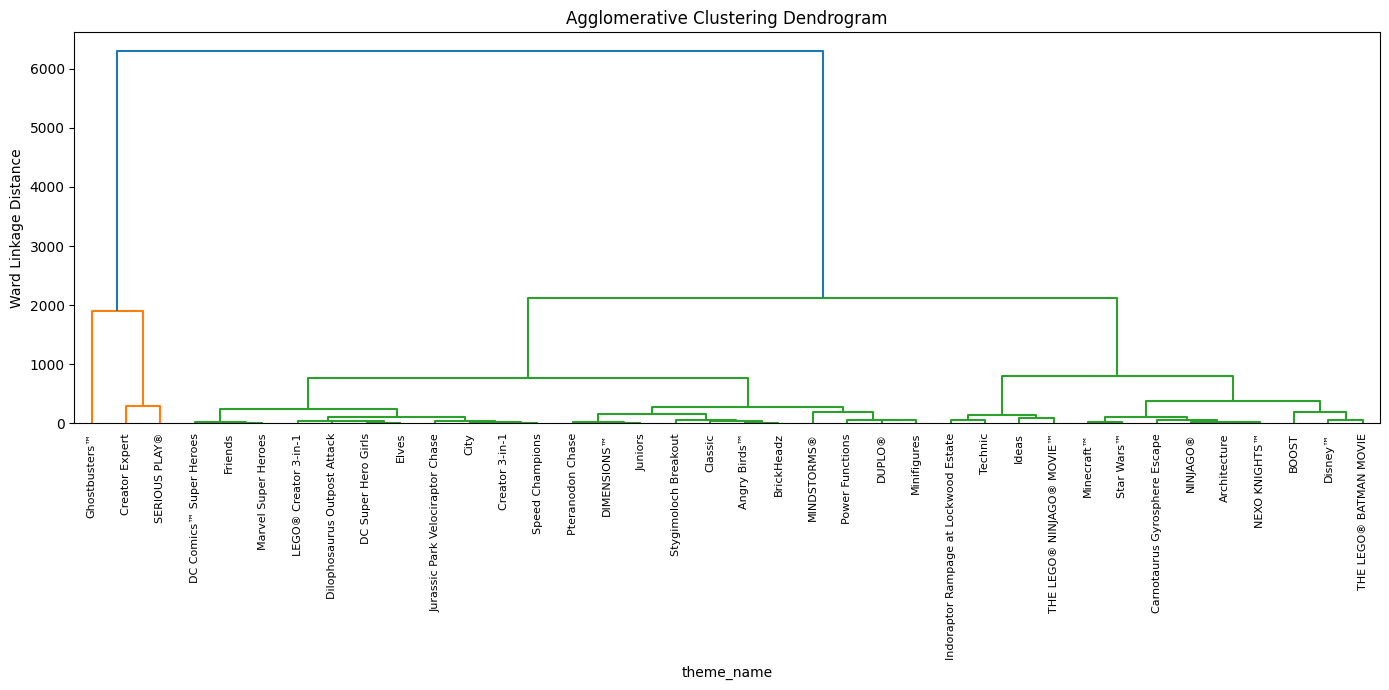

In [76]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    labels=category_aggregates['theme_name'].values,
    leaf_rotation=90
)

plt.title('Agglomerative Clustering Dendrogram')
plt.xlabel('theme_name')
plt.ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.show()

In [77]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# if you can get both these metrics either 1 or very close to 1
# is means the clustering describes the original structure extremely well
# and you can replace the original high cardinality column with the cluster values instead

# Silhouette Score
sil_score = silhouette_score(
    X_scaled,
    category_aggregates['Cluster']
)

# ARI
ari_score = adjusted_rand_score(
    category_aggregates['theme_name'],
    category_aggregates['Cluster']
)

print(f"Silhouette Score: {sil_score:.4f}")

# ARI doesn't help here since we are trying to measure a different thing here
# replacement for the original category
print(f"Adjusted Rand Index: {ari_score:.4f}")

Silhouette Score: 0.5033
Adjusted Rand Index: 0.0000


Mapping the cluster back into its original dataframe

In [ ]:
category_mapping = category_aggregates[
    ['theme_name', 'Cluster']
].copy()

In [79]:
df = df.merge(
    category_mapping,
    on='theme_name',
    how='left'
)

df = df.drop('theme_name', axis=1)

In [80]:
df

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,continent_Europe,continent_North America,continent_Oceania,price_per_brick,min_age,Cluster
0,29.9900,2.0,277.0,4.0,2.0,4.5,4.0,0,1,0,0.1083,6.0,0
1,19.9900,2.0,168.0,4.0,1.0,5.0,4.0,0,1,0,0.1190,6.0,0
2,12.9900,11.0,74.0,4.3,1.0,4.3,4.1,0,1,0,0.1755,6.0,0
3,99.9900,23.0,1032.0,3.6,2.0,4.6,4.3,0,1,0,0.0969,12.0,6
4,79.9900,14.0,744.0,3.2,3.0,4.6,4.1,0,1,0,0.1075,12.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5884,213.4878,6.0,1413.0,4.3,2.0,4.3,3.7,1,0,0,0.1511,9.0,6
5885,153.7078,15.0,825.0,4.7,2.0,4.7,4.3,1,0,0,0.1863,9.0,6
5886,19.5078,6.0,102.0,4.2,0.0,4.2,4.3,1,0,0,0.1913,6.0,6
5887,19.5078,6.0,99.0,4.6,0.0,5.0,4.4,1,0,0,0.1970,6.0,6


In [83]:
# average list_price per cluster. Looks like the prices vary quite a bit between the clusters?
df.groupby("Cluster")["list_price"].mean()

Cluster
0     35.954886
1     91.536520
2     48.738551
3    387.877539
4    100.028483
5    460.329178
6     82.635484
7    204.630461
Name: list_price, dtype: float64

In [84]:
df.groupby("Cluster")["piece_count"].mean()

# Similar findings with piece_count!

Cluster
0     112.252590
1     726.977376
2     363.683270
3    4180.888889
4     986.242836
5    2499.422222
6     609.215450
7    2584.163462
Name: piece_count, dtype: float64

In my opinion, the 'theme_name' column is in a much more digestiable form. Easier to use as a hue, and it's always possible to go back and see the names of the themes in the clusters and draw more conclusions. 

## Step 2a: Select a dataset that may benefit from interaction features

I will keep using the lego dataset!

## Step 2b: Create some new features using feature interaction.